# 02 — Baseline: SEIRD con β costante

Obiettivo: stimare i parametri del SEIRD con **β costante** in ogni finestra temporale. 
È il termine di confronto per il nostro contibuto con GP: β(t), non costante, è invece dipendente dalla mobilità. Idealmente, dovrebbe fare meglio di così.

Impostazione, come nel paper del 21/22:
- parametri stimati: β, σ, γ, μ e gli esposti iniziali E₀ (non osservati, dove: 
        - beta: tasso di trasmissione
        - sigma: 1/sigma è la durata media dell'incubazione 
        - gamma: tasso di guarigione
        - mu: tasso di morte)
        --> ne deriviamo due quantità: 
            -t_inf: 1/(gamma+mu), giorni medi passati nel compartment Infected 
            -f: mu/(gamma+mu), frazione di I che va in D (muore).  

- condizioni iniziali di I, R, D prese dai dati del primo giorno della finestra;
- fitness = 0.9 · RMSD(decessi) + 0.1 · RMSD(positivi attuali);
- ottimizzatore: differential evolution (algoritmo evolutivo di scipy).

Sezioni:
1. Replica del primo esperimento del paper (dati `raw`, 1/3–1/4/2020)
2. Baseline con divisione train/test su tutte le finestre, `raw` e `clean`
3. Diagnostica: identificabilità dei parametri
4. Conclusioni e decisioni aperte

In [1]:
import time
import pandas as pd
import matplotlib.pyplot as plt

from seird_gp.data import PROCESSED_DIR, RESULTS_DIR
from seird_gp.fitting import DEFAULT_BOUNDS, fit_baseline, relative_fitness

data = {name: pd.read_csv(PROCESSED_DIR / f"trento_{name}.csv", index_col=0, parse_dates=True)
        for name in ["raw", "clean"]}
WINDOWS = {"2020 (1/3–1/4)": ("2020-03-01", "2020-04-01"),
           "2021 (1/3–1/6)": ("2021-03-01", "2021-06-01"),
           "2022 (1/1–1/3)": ("2022-01-01", "2022-03-01")}
TRAIN_FRAC = 2 / 3
RESULTS_DIR.mkdir(exist_ok=True)
pd.DataFrame(DEFAULT_BOUNDS, index=["min", "max"])

,beta,sigma,gamma,mu
min,0.01,0.071429,0.016667,0.00
max,2.00,0.500000,0.333333,0.05


In [2]:
def plot_fit(res, obs, title, ax_pair):
    for ax, model, col, label in [(ax_pair[0], "D", "deceduti", "Decessi (cumulativi)"),
                                  (ax_pair[1], "I", "totale_positivi", "Positivi attuali")]:
        ax.plot(obs.index, obs[col], "o", ms=3, color="#999", label="dati")
        ax.plot(res.simulation.index, res.simulation[model], color="#1f4e79", label="modello")
        if res.train_end < obs.index[-1]:
            ax.axvspan(res.train_end, obs.index[-1], color="#f4e3c1", alpha=0.6, label="test")
        ax.set_title(f"{title} — {label}", fontsize=9)
        ax.spines[["top", "right"]].set_visible(False)
        ax.tick_params(axis="x", labelrotation=30, labelsize=8)

## 1. Replica del paper

Primo esperimento di Pianesi e Pojer: dati originali, 1/3–1/4/2020, fit su tutta la finestra. La loro Tabella I usa una parametrizzazione diversa (t_inf, f); la convertiamo:
- t_inf = 1 / (γ + μ): giorni medi in I
- f = μ / (γ + μ): frazione di chi esce da I che muore
- R0 = β / (γ + μ)

In [3]:
a, b = WINDOWS["2020 (1/3–1/4)"]
paper = fit_baseline(data["raw"], a, b, train_frac=1.0)
cmp = pd.DataFrame({
    "Pianesi e Pojer": {"beta": 0.47, "sigma": 1.52, "t_inf": 5.1, "f": 0.37, "fitness": 12.50},
    "nostro": {"beta": paper.params["beta"], "sigma": paper.params["sigma"],
               "t_inf": paper.derived()["t_inf"], "f": paper.derived()["f"],
               "fitness": paper.fitness_train},
}).round(3)
print("Parametri sul bordo dell'intervallo:", paper.extra["at_bound"])
cmp

Parametri sul bordo dell'intervallo: ['sigma', 'gamma']


,Pianesi e Pojer,nostro
beta,0.47,0.324
sigma,1.52,0.071
t_inf,5.10,36.906
f,0.37,0.385
fitness,12.50,24.179


commento: alcuni valori sono assolutamente fuori scala. sigma e gamma sono al limite. ne esce un'epidemia lentissima, non realistica (incubazione 37 giorni è tosta)

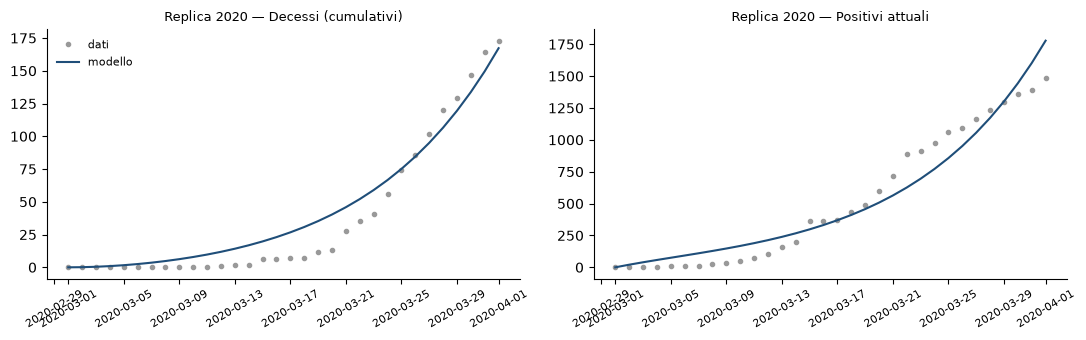

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
plot_fit(paper, data["raw"].loc[a:b], "Replica 2020", ax)
ax[0].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(RESULTS_DIR / "02_replica_paper.png", dpi=150)

**Lettura.**
- La frazione di decessi f è vicina a quella del paper (~0.38 contro 0.37).
- σ e t_inf sono molto diversi. Il paper ha σ = 1.52, cioè un'incubazione di meno di un giorno: biologicamente implausibile, possibile solo perché il loro intervallo per σ era più largo. Noi limitiamo l'incubazione a 2–14 giorni, e σ finisce sul bordo inferiore.


Conclusione: l'implementazione si comporta in modo coerente col paper, ma i parametri dipendono molto dagli intervalli, come scrivono anche gli autori.

**proposta**
Fissare sigma e gamma da letteratura può aiutare?--> probabilmente si (DA FARE: RICERCA BIBLIOGRAFICA)
Anzi, probabilmente è solo meglio: se nella parte successiva co  GP sigma e gamma saranno fixed da literaturem, ha senso che lo siano già per un confronto più robusto. 

**Confronto alla pari con il codice del paper**

Il codice di Pianesi e Pojer ([LunaBaozi/SEIRD-covid-models-with-GAs](https://github.com/LunaBaozi/SEIRD-covid-models-with-GAs), `SEIRD_model/seird_problem.py` e `runner.py`) non coincide con il testo del paper:

| | Testo del paper / nostra replica | Loro codice |
|---|---|---|
| Fitness | 0.9 · RMSE(decessi) + 0.1 · RMSE(**positivi**) | 0.9 · RMSE(decessi) + 0.1 · RMSE(**guariti**) |
| t_inf | stimato | fissato a 5.1 |
| γ | stimato | ottimizzato ma non usato nelle equazioni |
| E₀ | stimato | fissato a 1 |
| Finestra | 1/3–1/4 | 1/3–31/3 |
| Griglia temporale | 1 giorno | `linspace(0, 31, 31)`: passo di 1.033 giorni |
| Intervalli | σ in [1/14, 1/2] | β in [0, 5], σ in [0.1, 17], f in [0, 1] |

Nel loro codice i pesi 0.9/0.1 non guidano NSGA-II, che è multi-obiettivo: servono solo a calcolare il numero riportato.

Sotto: (1) riproduciamo il loro 12.50 con il loro modello; (2) rifacciamo il confronto con la loro metrica.

In [5]:
import numpy as np
from scipy.integrate import odeint
from seird_gp.fitting import pianesi_pojer_fitness, rmsd

pp_obs = data["raw"].loc["2020-03-01":"2020-03-31"]   # la loro finestra (fine esclusa)
N_PP, T_INF_PP = 542166, 5.1

def pp_model(x, t, beta, sigma, f):
    """SEIRD del loro codice: t_inf fisso, f = frazione dei decessi."""
    S, E, I, R, D = x
    return [-beta * S * I / N_PP, beta * S * I / N_PP - sigma * E, sigma * E - I / T_INF_PP,
            (1 - f) / T_INF_PP * I, f / T_INF_PP * I]

first = pp_obs.iloc[0]
x0 = [N_PP - 1 - first.totale_positivi - first.dimessi_guariti - first.deceduti, 1,
      first.totale_positivi, first.dimessi_guariti, first.deceduti]
for grid_name, t in [("loro griglia (passo 1.033 gg)", np.linspace(0, len(pp_obs), len(pp_obs))),
                     ("griglia giornaliera", np.arange(len(pp_obs), dtype=float))]:
    s = pd.DataFrame(odeint(pp_model, x0, t, args=(0.47, 1.52, 0.37)),
                     columns=["S", "E", "I", "R", "D"], index=pp_obs.index)
    print(f"Parametri del paper, {grid_name}: decessi+guariti = {pianesi_pojer_fitness(s, pp_obs):.2f}, "
          f"decessi+positivi = {0.9 * rmsd(s.D, pp_obs.deceduti) + 0.1 * rmsd(s.I, pp_obs.totale_positivi):.2f}")

rows = {"Pianesi e Pojer (Tabella I)": {"fitness decessi+guariti": 12.50, "beta": 0.47, "sigma": 1.52,
                                        "t_inf": 5.1, "f": 0.37, "al bordo": ""}}
rows["nostro fit sezione 1, rivalutato"] = {
    "fitness decessi+guariti": pianesi_pojer_fitness(paper.simulation.loc[pp_obs.index], pp_obs),
    "beta": paper.params["beta"], "sigma": paper.params["sigma"], **{k: paper.derived()[k] for k in ["t_inf", "f"]},
    "al bordo": ", ".join(paper.extra["at_bound"])}
for name, kw in [("nostro codice, loro metrica", {}),
                 ("nostro codice, loro metrica, E0 = 1 e intervalli larghi",
                  {"fixed": {"E0": 1.0}, "bounds": {"sigma": (0.1, 17), "gamma": (0, 1)}})]:
    r = fit_baseline(data["raw"], "2020-03-01", "2020-03-31", fitness_fn=pianesi_pojer_fitness, **kw)
    rows[name] = {"fitness decessi+guariti": r.fitness_train, "beta": r.params["beta"], "sigma": r.params["sigma"],
                  **{k: r.derived()[k] for k in ["t_inf", "f"]}, "al bordo": ", ".join(r.extra["at_bound"])}
pd.DataFrame(rows).T.round(3)

Parametri del paper, loro griglia (passo 1.033 gg): decessi+guariti = 12.50, decessi+positivi = 64.66
Parametri del paper, griglia giornaliera: decessi+guariti = 15.91, decessi+positivi = 71.75


,fitness decessi+guariti,beta,sigma,t_inf,f,al bordo
Pianesi e Pojer (Tabella I),12.5,0.47,1.52,5.1,0.37,
"nostro fit sezione 1, rivalutato",14.184631,0.324401,0.071429,36.905664,0.384905,"sigma, gamma"
"nostro codice, loro metrica",7.180379,0.661545,0.071429,33.357732,0.443999,"sigma, gamma"
"nostro codice, loro metrica, E0 = 1 e intervalli larghi",11.620141,0.345021,16.999992,8.832905,0.441645,"sigma, mu"


**Lettura.**
- Il 12.50 del paper si riproduce esattamente con **decessi + guariti** sulla loro griglia temporale. Con i positivi, come dice il testo, verrebbe circa 65. Il 24 della nostra replica non era confrontabile.
- Con la stessa metrica il nostro codice trova **7.2**, meglio del loro 12.5. Quindi la nostra implementazione non è peggiore: il gap veniva dalla metrica diversa.
- Anche con la loro metrica i parametri finiscono al bordo: con i nostri intervalli σ e γ al minimo, con i loro intervalli σ = 17 (incubazione di un'ora e mezza) e μ al massimo. Il problema di identificabilità c'è anche nel loro lavoro, solo che non lo segnalano.
- Nel resto del notebook la fitness resta quella del testo (decessi + positivi) e, dalla sezione 5, quella normalizzata. `pianesi_pojer_fitness` serve solo per questo confronto.

## 2. Baseline train/test

In ogni finestra: fit sui primi 2/3 dei giorni, test sull'ultimo terzo. È la stessa divisione che useremo per il GP.

In [5]:
rows, fits = [], {}
t0 = time.time()
for ds in ["raw", "clean"]:
    for name, (a, b) in WINDOWS.items():
        res = fit_baseline(data[ds], a, b, train_frac=TRAIN_FRAC)
        fits[(ds, name)] = res
        rows.append({"dataset": ds, "finestra": name, **res.params, **res.derived(),
                     "RMSD D train": res.rmsd.loc["train", "D"], "RMSD D test": res.rmsd.loc["test", "D"],
                     "RMSD I train": res.rmsd.loc["train", "I"], "RMSD I test": res.rmsd.loc["test", "I"],
                     "fitness test": res.rmsd.loc["test", "fitness"],
                     "al bordo": ", ".join(res.extra["at_bound"])})
print(f"{len(rows)} fit in {time.time() - t0:.0f} s")
baseline = pd.DataFrame(rows).set_index(["dataset", "finestra"])
baseline.round(3)

6 fit in 150 s


beta  sigma  gamma     mu         E0      R0   t_inf  \
dataset finestra                                                                
raw     2020 (1/3–1/4)  0.789  0.071  0.017  0.005    108.053  36.044  45.694   
        2021 (1/3–1/6)  0.010  0.071  0.056  0.001   5369.442   0.177  17.729   
        2022 (1/1–1/3)  0.567  0.500  0.333  0.000  12451.128   1.702   2.999   
clean   2020 (1/3–1/4)  0.782  0.071  0.017  0.004    119.050  37.594  48.096   
        2021 (1/3–1/6)  0.010  0.071  0.056  0.001   5369.442   0.177  17.729   
        2022 (1/1–1/3)  0.567  0.500  0.333  0.000  12451.128   1.702   2.999   

                            f  RMSD D train  RMSD D test  RMSD I train  \
dataset finestra                                                         
raw     2020 (1/3–1/4)  0.238         2.428       28.822        40.935   
        2021 (1/3–1/6)  0.013         7.360       10.706       169.601   
        2022 (1/1–1/3)  0.000         2.272       16.164      1186.599   
clean   2020 (1/3–1/4)  0.198         2.114       25.324        44.334   
        2021 (1/3–1/6)  0.013         7.360       10.706       169.601   
        2022 (1/1–1/3)  0.000         2.272       16.164      1186.599   

                        RMSD I test  fitness test          al bordo  
dataset finestra                                                     
raw     2020 (1/3–1/4)     2185.583       244.498      sigma, gamma  
        2021 (1/3–1/6)      169.680        26.603       beta, sigma  
        2022 (1/1–1/3)     1083.191       122.867  sigma, gamma, mu  
clean   2020 (1/3–1/4)     2345.604       257.352      sigma, gamma  
        2021 (1/3–1/6)      169.680        26.603       beta, sigma  
        2022 (1/1–1/3)     1083.191       122.867  sigma, gamma, mu

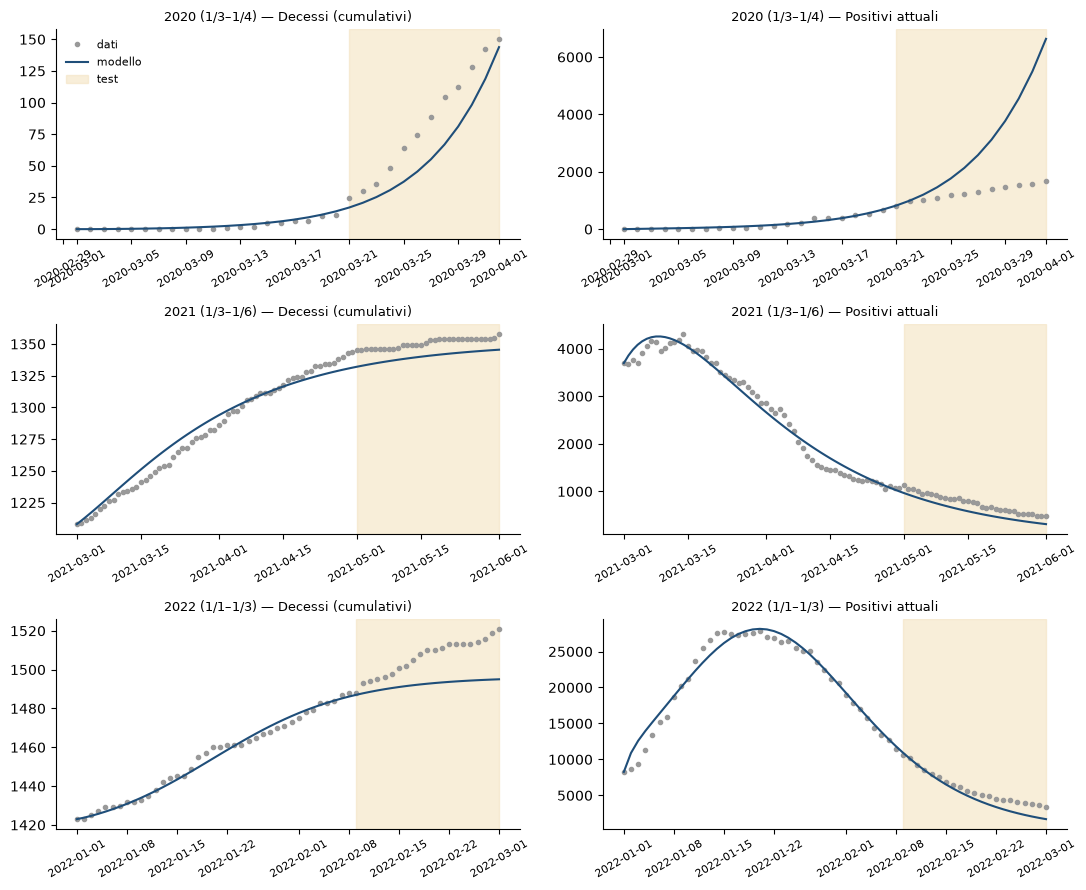

In [6]:
fig, ax = plt.subplots(3, 2, figsize=(11, 9))
for i, name in enumerate(WINDOWS):
    a, b = WINDOWS[name]
    plot_fit(fits[("clean", name)], data["clean"].loc[a:b], name, ax[i])
ax[0, 0].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(RESULTS_DIR / "02_baseline_clean.png", dpi=150)

In [7]:
baseline.to_csv(RESULTS_DIR / "02_baseline.csv")

effettivamente questo approccio ha un limite: manca ogni tipo di informazione legata al cambiamento del numero di contatti nel tempo (l'effetto diretto di social distancing, quarantena...)
obiettivo sarebbe dimostrare che un risultato migliore si ottiene modellando beta (t) come una funzione della mobilità (attraverso l'uso della GP)

## 3. Diagnostica: identificabilità

Limiti gia visti: bisogna provare a fissare sigma e gamma e vedere se correggiamo
Molti parametri finiscono sul bordo dell'intervallo. Significa che l'ottimizzatore vorrebbe andare oltre, oppure che il valore non conta perché combinazioni diverse danno curve quasi uguali. In entrambi i casi i parametri non sono **identificabili** dai soli dati di D e I.

Tre controlli sui dati `clean`:
- **(a) seed diversi**: se i parametri cambiano molto da un seed all'altro, non sono determinati dai dati;
- **(b) σ fissato** a 1/5.2 (incubazione media a caso, bisogna guardare un po papers): toglie un grado di libertà --> serve analisi di letteratura!!!;
- **(c) fitness relativa con i guariti**: errori normalizzati e R confrontato con `dimessi_guariti`, per vincolare γ.

In [8]:
rows = []
for name, (a, b) in WINDOWS.items():
    for seed in [1, 2]:
        r = fit_baseline(data["clean"], a, b, train_frac=TRAIN_FRAC, seed=seed)
        rows.append({"finestra": name, "variante": f"(a) seed {seed}", **r.params, **r.derived(),
                     "RMSD D test": r.rmsd.loc["test", "D"], "RMSD I test": r.rmsd.loc["test", "I"],
                     "al bordo": ", ".join(r.extra["at_bound"])})
    r = fit_baseline(data["clean"], a, b, train_frac=TRAIN_FRAC, fixed={"sigma": 1 / 5.2})
    rows.append({"finestra": name, "variante": "(b) σ = 1/5.2", **r.params, **r.derived(),
                 "RMSD D test": r.rmsd.loc["test", "D"], "RMSD I test": r.rmsd.loc["test", "I"],
                 "al bordo": ", ".join(r.extra["at_bound"])})
    r = fit_baseline(data["clean"], a, b, train_frac=TRAIN_FRAC, fixed={"sigma": 1 / 5.2},
                     fitness_fn=relative_fitness)
    rows.append({"finestra": name, "variante": "(c) σ fisso + fitness relativa", **r.params, **r.derived(),
                 "RMSD D test": r.rmsd.loc["test", "D"], "RMSD I test": r.rmsd.loc["test", "I"],
                 "al bordo": ", ".join(r.extra["at_bound"])})
base_rows = baseline.loc["clean"].reset_index().assign(variante="seed 0 (sezione 2)")
diag = pd.concat([base_rows, pd.DataFrame(rows)])
cols = ["finestra", "variante", "beta", "sigma", "gamma", "mu", "E0", "R0", "RMSD D test", "RMSD I test", "al bordo"]
diag = diag[cols].sort_values(["finestra", "variante"]).set_index(["finestra", "variante"])
diag.to_csv(RESULTS_DIR / "02_diagnostica.csv")
diag.round(3)

beta  sigma  gamma     mu  \
finestra       variante                                                     
2020 (1/3–1/4) (a) seed 1                      0.782  0.071  0.017  0.004   
               (a) seed 2                      0.782  0.071  0.017  0.004   
               (b) σ = 1/5.2                   0.428  0.192  0.017  0.004   
               (c) σ fisso + fitness relativa  1.046  0.192  0.017  0.010   
               seed 0 (sezione 2)              0.782  0.071  0.017  0.004   
2021 (1/3–1/6) (a) seed 1                      0.338  0.500  0.333  0.001   
               (a) seed 2                      0.010  0.071  0.056  0.001   
               (b) σ = 1/5.2                   0.010  0.192  0.037  0.001   
               (c) σ fisso + fitness relativa  0.053  0.192  0.073  0.001   
               seed 0 (sezione 2)              0.010  0.071  0.056  0.001   
2022 (1/1–1/3) (a) seed 1                      0.567  0.500  0.333  0.000   
               (a) seed 2                      0.567  0.500  0.333  0.000   
               (b) σ = 1/5.2                   0.607  0.192  0.333  0.000   
               (c) σ fisso + fitness relativa  0.069  0.192  0.068  0.000   
               seed 0 (sezione 2)              0.567  0.500  0.333  0.000   

                                                      E0      R0  RMSD D test  \
finestra       variante                                                         
2020 (1/3–1/4) (a) seed 1                        119.055  37.593       25.324   
               (a) seed 2                        119.041  37.596       25.321   
               (b) σ = 1/5.2                      54.190  20.607       24.834   
               (c) σ fisso + fitness relativa      3.590  39.759      317.273   
               seed 0 (sezione 2)                119.050  37.594       25.324   
2021 (1/3–1/6) (a) seed 1                       3912.311   1.013        7.197   
               (a) seed 2                       5369.459   0.177       10.706   
               (b) σ = 1/5.2                    2300.941   0.262        7.656   
               (c) σ fisso + fitness relativa   2502.658   0.718        4.852   
               seed 0 (sezione 2)               5369.442   0.177       10.706   
2022 (1/1–1/3) (a) seed 1                      12451.175   1.702       16.165   
               (a) seed 2                      12450.980   1.702       16.168   
               (b) σ = 1/5.2                   38304.891   1.821       12.495   
               (c) σ fisso + fitness relativa  26923.228   1.011        4.832   
               seed 0 (sezione 2)              12451.128   1.702       16.164   

                                               RMSD I test          al bordo  
finestra       variante                                                       
2020 (1/3–1/4) (a) seed 1                         2345.579      sigma, gamma  
               (a) seed 2                         2345.917      sigma, gamma  
               (b) σ = 1/5.2                      2419.920             gamma  
               (c) σ fisso + fitness relativa    13009.152         gamma, E0  
               seed 0 (sezione 2)                 2345.604      sigma, gamma  
2021 (1/3–1/6) (a) seed 1                           46.243      sigma, gamma  
               (a) seed 2                          169.686       beta, sigma  
               (b) σ = 1/5.2                        32.281              beta  
               (c) σ fisso + fitness relativa      401.052                    
               seed 0 (sezione 2)                  169.680       beta, sigma  
2022 (1/1–1/3) (a) seed 1                         1083.206  sigma, gamma, mu  
               (a) seed 2                         1083.187  sigma, gamma, mu  
               (b) σ = 1/5.2                      2405.812         gamma, mu  
               (c) σ fisso + fitness relativa    10554.214                mu  
               seed 0 (sezione 2)                 1083.191  sigma, gamma, mu

## 4. Conclusioni

- **Il codice funziona**: sui dati sintetici (test in `tests/test_fitting.py`) il fit ritrova i parametri veri, e sul 2020 il risultato è coerente con il paper.
- **I parametri del SEIRD a β costante non sono identificabili** dai soli decessi e positivi: finiscono sui bordi e cambiano con le scelte di modellazione (σ fisso, fitness). Le curve fittate però sono simili. Va tenuto presente quando si interpretano i valori numerici: conta l'errore, non i singoli parametri.
- **β costante non può seguire i cambi di fase.** Nella finestra 2020 c'è il lockdown (9/3/2020), nella 2021 l'epidemia è in calo. Il modello compensa con valori estremi (R0 ≈ 37 nel 2020, β al minimo nel 2021) e sbaglia nel periodo di test: nel 2020 prevede una crescita esponenziale che il lockdown ha fermato (RMSD sui positivi in test > 2000). È proprio la limitazione che il GP con β(t) deve superare.
- `raw` e `clean` differiscono solo nel 2020, e di poco.

il riferimento per il GP è la baseline con σ e γ fissati (`results/02_baseline_letteratura.csv`).

## TBD

1. **Quale fitness usare d'ora in poi.** Quella del paper (0.9/0.1 su RMSD assolute) fa pesare molto gli infetti, perché sono migliaia mentre i decessi sono decine. La versione relativa (c) bilancia i termini e usa anche i guariti. proposta: fitness normalizzata su decessi e positivi.
2. **Fissare σ dalla letteratura?** Riduce un grado di libertà senza costi evidenti. Con β(t) il problema di identificabilità aumenta, perché i gradi di libertà sono di più, quindi fissare ciò che si può fissare aiuta. → σ e γ fissati, con sensibilità su γ.
3. **Le finestre.** Quelle del paper sono brevi (1–3 mesi). Per il GP potrebbero servire finestre più lunghe con variazioni di mobilità, per esempio da settembre 2020 a febbraio 2021 per la seconda ondata.

## 5. Baseline con σ e γ da letteratura e fitness normalizzata

Decisione del 10/11/2026, presa **prima** del GP e valida sia per la baseline sia per il GP.

- **σ = 1/5.2.** Incubazione media 5,2 giorni (IC 95% 4,1–7,0). preso da un paper cinese su wuhan quindi va guardato meglio
- **γ fissato, con analisi di sensibilità.** Nel modello I si confronta con `totale_positivi`, cioè con chi è *registrato* come positivo, non con chi è *infettivo*. Le due durate sono diverse:
  - infettività: circa 7–10 giorni, con stime molto variabili (Byrne et al., *BMJ Open* 2020, doi:10.1136/bmjopen-2020-039856). Dopo il 9° giorno dai sintomi il virus vivo non si isola più in coltura (Cevik et al., *Lancet Microbe* 2021, PMC7837230);
  - positività registrata: mediana 30 giorni dalla diagnosi al primo tampone negativo, Reggio Emilia, primavera 2020 (Mancuso et al., *BMJ Open* 2020, doi:10.1136/bmjopen-2020-040380).
 
 
 
 **i riferimenti sono tutti da controllare bene!!!!!**

  Proviamo γ = 1/10, 1/20, 1/30. Se le conclusioni cambiano con γ, vanno riportate condizionate a γ. I tempi di negativizzazione e le regole di isolamento sono cambiati nel tempo, quindi un γ unico per tutte le finestre è un'approssimazione.
- **Fitness normalizzata** (`normalized_fitness`): 0.5 · RMSD(D)/std(D) + 0.5 · RMSD(I)/std(I), con le deviazioni standard calcolate sul training. Pesi uguali: nessuna preferenza a priori. Niente guariti, perché `dimessi_guariti` è il dato meno affidabile.
- Restano da stimare β, μ ed E₀. Divisione train/test come nella sezione 2, dati `clean`.

Per confronto riportiamo anche la baseline libera della sezione 2, valutata con la stessa fitness normalizzata.

In [9]:
from seird_gp.fitting import SIGMA_LIT, normalized_fitness

GAMMAS = {"γ = 1/10 (infettività)": 1 / 10, "γ = 1/20": 1 / 20, "γ = 1/30 (positività)": 1 / 30}

def summary(res):
    return {**{k: res.params[k] for k in ["beta", "sigma", "gamma", "mu", "E0"]}, **res.derived(),
            "RMSD D test": res.rmsd.loc["test", "D"], "RMSD I test": res.rmsd.loc["test", "I"],
            "fitness_norm train": res.rmsd.loc["train", "fitness_norm"],
            "fitness_norm test": res.rmsd.loc["test", "fitness_norm"],
            "al bordo": ", ".join(res.extra["at_bound"])}

rows, fits_lit = [], {}
t0 = time.time()
for name, (a, b) in WINDOWS.items():
    for label, g in GAMMAS.items():
        res = fit_baseline(data["clean"], a, b, train_frac=TRAIN_FRAC,
                           fixed={"sigma": SIGMA_LIT, "gamma": g}, fitness_fn=normalized_fitness)
        fits_lit[(name, label)] = res
        rows.append({"finestra": name, "variante": label, **summary(res)})
    rows.append({"finestra": name, "variante": "libera (sezione 2)", **summary(fits[("clean", name)])})
print(f"{len(GAMMAS) * len(WINDOWS)} fit in {time.time() - t0:.0f} s")
baseline_lit = pd.DataFrame(rows).set_index(["finestra", "variante"])
baseline_lit.to_csv(RESULTS_DIR / "02_baseline_letteratura.csv")
baseline_lit.round(3)

9 fit in 49 s


beta  sigma  gamma     mu         E0  \
finestra       variante                                                        
2020 (1/3–1/4) γ = 1/10 (infettività)  0.682  0.192  0.100  0.005     43.196   
               γ = 1/20                0.574  0.192  0.050  0.005     40.553   
               γ = 1/30 (positività)   0.538  0.192  0.033  0.005     39.672   
               libera (sezione 2)      0.782  0.071  0.017  0.004    119.050   
2021 (1/3–1/6) γ = 1/10 (infettività)  0.072  0.192  0.100  0.001   3741.137   
               γ = 1/20                0.023  0.192  0.050  0.001   2536.370   
               γ = 1/30 (positività)   0.010  0.192  0.033  0.001   1864.276   
               libera (sezione 2)      0.010  0.071  0.056  0.001   5369.442   
2022 (1/1–1/3) γ = 1/10 (infettività)  0.110  0.192  0.100  0.000  30873.515   
               γ = 1/20                0.041  0.192  0.050  0.000  26406.364   
               γ = 1/30 (positività)   0.020  0.192  0.033  0.000  24786.980   
               libera (sezione 2)      0.567  0.500  0.333  0.000  12451.128   

                                           R0   t_inf      f  RMSD D test  \
finestra       variante                                                     
2020 (1/3–1/4) γ = 1/10 (infettività)   6.524   9.562  0.044       20.073   
               γ = 1/20                10.520  18.324  0.084       20.051   
               γ = 1/30 (positività)   14.194  26.382  0.121       20.036   
               libera (sezione 2)      37.594  48.096  0.198       25.324   
2021 (1/3–1/6) γ = 1/10 (infettività)   0.717   9.925  0.007        5.705   
               γ = 1/20                 0.457  19.704  0.015        6.386   
               γ = 1/30 (positività)    0.293  29.336  0.022        4.051   
               libera (sezione 2)       0.177  17.729  0.013       10.706   
2022 (1/1–1/3) γ = 1/10 (infettività)   1.099   9.992  0.001        6.271   
               γ = 1/20                 0.816  19.968  0.002        6.695   
               γ = 1/30 (positività)    0.585  29.929  0.002        7.066   
               libera (sezione 2)       1.702   2.999  0.000       16.164   

                                       RMSD I test  fitness_norm train  \
finestra       variante                                                  
2020 (1/3–1/4) γ = 1/10 (infettività)     3435.831               0.263   
               γ = 1/20                   3435.541               0.262   
               γ = 1/30 (positività)      3434.013               0.262   
               libera (sezione 2)         2345.602               0.267   
2021 (1/3–1/6) γ = 1/10 (infettività)      110.503               0.211   
               γ = 1/20                     78.329               0.202   
               γ = 1/30 (positività)       184.651               0.205   
               libera (sezione 2)          169.680               0.160   
2022 (1/1–1/3) γ = 1/10 (infettività)     9304.698               0.373   
               γ = 1/20                   9228.746               0.361   
               γ = 1/30 (positività)      8928.060               0.353   
               libera (sezione 2)         1083.191               0.146   

                                       fitness_norm test          al bordo  
finestra       variante                                                     
2020 (1/3–1/4) γ = 1/10 (infettività)              8.591                    
               γ = 1/20                            8.588                    
               γ = 1/30 (positività)               8.584                    
               libera (sezione 2)                  6.840      sigma, gamma  
2021 (1/3–1/6) γ = 1/10 (infettività)              0.115                    
               γ = 1/20                            0.109              beta  
               γ = 1/30 (positività)               0.127              beta  
               libera (sezione 2)                  0.199       beta, sigma  
2022 (1/1–1/3) γ = 1/10 (infettiv

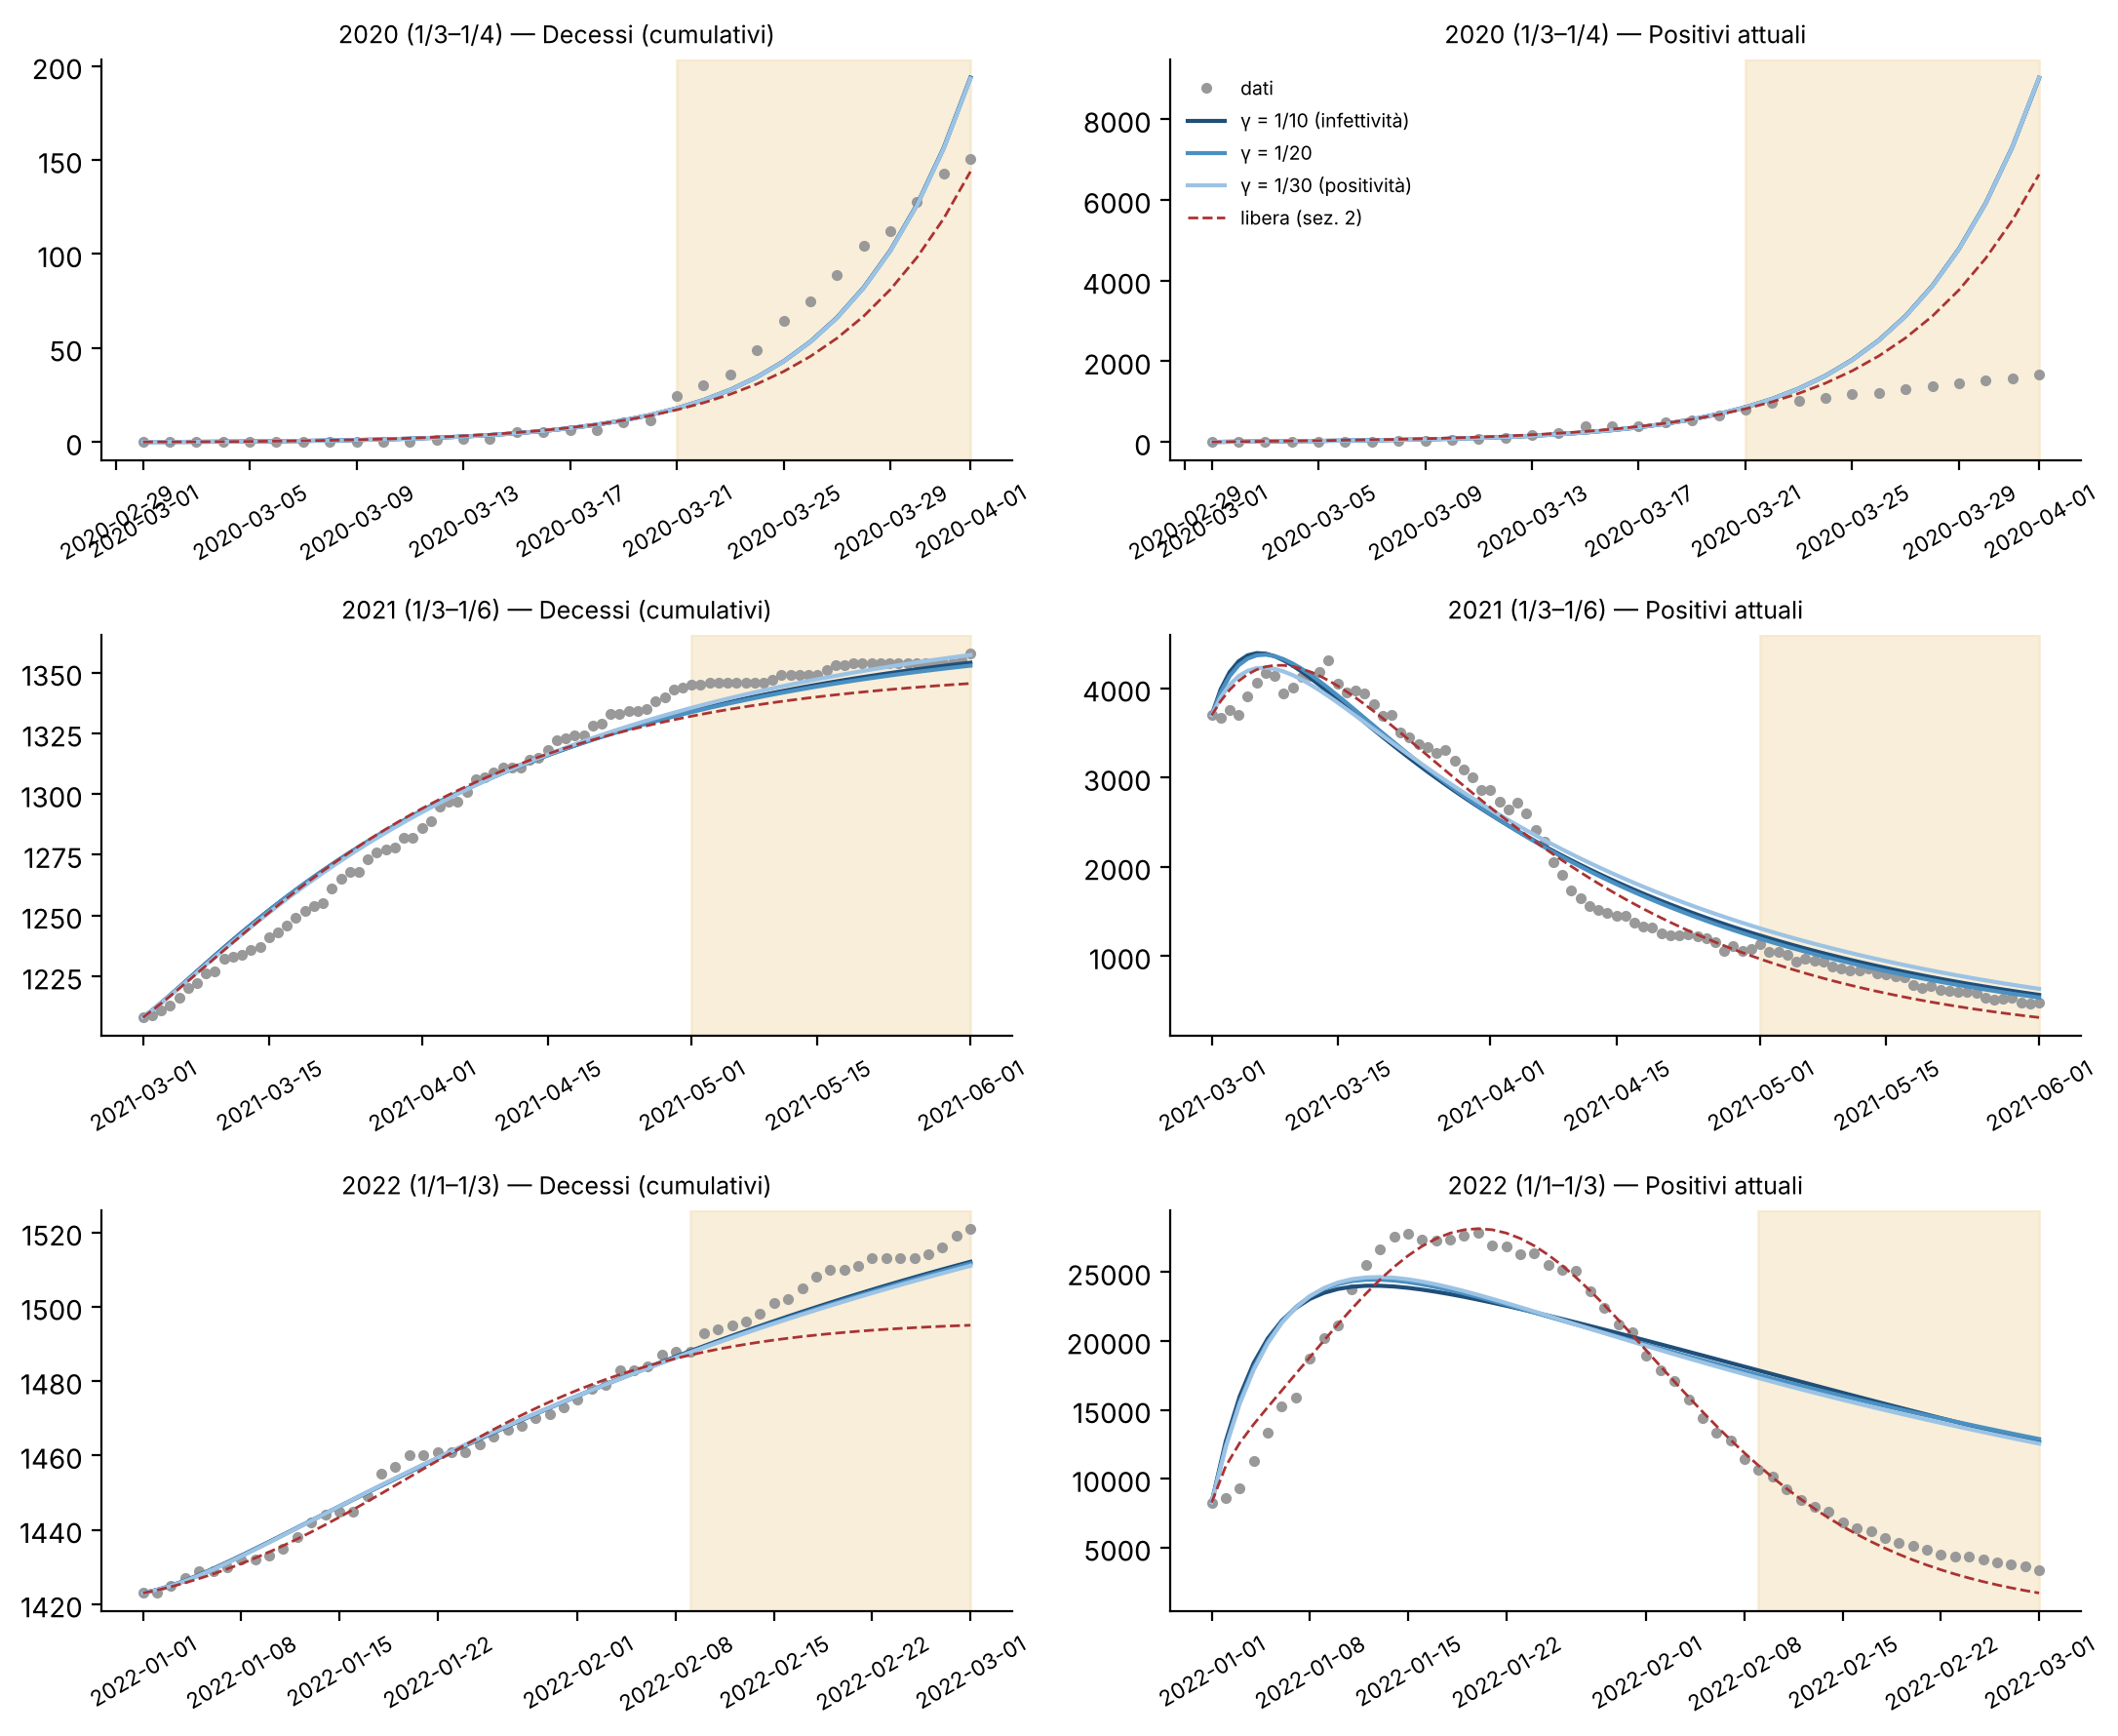

In [10]:
colors = {"γ = 1/10 (infettività)": "#1f4e79", "γ = 1/20": "#4a90c2", "γ = 1/30 (positività)": "#9cc3e4"}
fig, ax = plt.subplots(3, 2, figsize=(11, 9))
for i, (name, (a, b)) in enumerate(WINDOWS.items()):
    obs = data["clean"].loc[a:b]
    for j, (model, col, lab) in enumerate([("D", "deceduti", "Decessi (cumulativi)"),
                                           ("I", "totale_positivi", "Positivi attuali")]):
        axx = ax[i, j]
        axx.plot(obs.index, obs[col], "o", ms=3, color="#999", label="dati")
        for label, c in colors.items():
            axx.plot(fits_lit[(name, label)].simulation[model], color=c, label=label)
        axx.plot(fits[("clean", name)].simulation[model], "--", color="#a33", lw=1, label="libera (sez. 2)")
        axx.axvspan(fits[("clean", name)].train_end, obs.index[-1], color="#f4e3c1", alpha=0.6)
        axx.set_title(f"{name} — {lab}", fontsize=9)
        axx.spines[["top", "right"]].set_visible(False)
        axx.tick_params(axis="x", labelrotation=30, labelsize=8)
ax[0, 1].legend(frameon=False, fontsize=7)
fig.tight_layout(); fig.savefig(RESULTS_DIR / "02_baseline_letteratura.png", dpi=150)

**Lettura.**

- **Parametri plausibili, problemi al bordo quasi spariti.** Restano:
  - β = 0.010 nel 2021 con γ = 1/30: è davvero al minimo. Con 30 giorni in I, un'epidemia in calo richiederebbe un β ancora più basso dell'intervallo;
  - μ nel 2022 (≈ 8·10⁻⁵) e β = 0.02–0.04 nel 2021–2022 sono segnalati, ma sono falsi allarmi: il controllo usa l'1% di intervalli larghi ([0, 0.05] per μ, [0.01, 2] per β), e valori piccoli ma sensati ci cadono dentro.
- **γ non è identificabile, come previsto.** Nel 2020 la fitness è la stessa con tutti e tre i γ (train 0.26, test 8.59), ma R0 va da 6.5 a 14. R0 lo decide γ, non i dati: va sempre riportato insieme al γ scelto.
- **L'errore fuori campione dipende dalla finestra** (fitness_norm test, fissata contro libera):
  - 2021: meglio (0.11–0.13 contro 0.20);
  - 2020: peggio (8.6 contro 6.8), per colpa dei positivi; sui decessi invece è meglio (RMSD test 20 contro 25). In ogni variante l'errore sui positivi nel test supera 2000: β costante non segue il lockdown, e fissare σ e γ non cambia questo limite. Nel grafico le tre curve con γ diversi sono sovrapposte;
  - 2022: peggio (0.86–0.87 contro 0.47), sempre per i positivi; sui decessi è meglio (RMSD test 6–7 contro 16). La baseline libera trova t_inf = 3 giorni: con Omicron le persone restavano fra i positivi per meno tempo, e nessuno dei γ provati (10–30 giorni) lo rappresenta.

**Conseguenze per il GP.**
- Il termine di confronto per il GP è questa tabella (`fitness_norm test`, `results/02_baseline_letteratura.csv`), con gli stessi σ e γ, non la sezione 2.
- Il GP va lanciato con gli stessi tre valori di γ.
- **TBD** il 2022 suggerisce che la durata di positività cambia nel tempo. Da decidere se usare un γ diverso per ogni finestra (servono fonti per il 2022) oppure limitare il GP al 2020–2021.